# ε time–height
Read `epsi_stare_vn_chunks_r20260517_2352.nc` and plot log₁₀ TKE dissipation rate for a DateTime window.
Blank pixels: ε ≤ 0 or missing.

In [1]:
using Pkg; Pkg.activate(".")
using Dates
using Statistics
using NCDatasets
using PythonPlot

m2n(x) = ismissing(x) ? NaN : x

rc("font", family="sans-serif")
rc("font"; Symbol("sans-serif") => "Arial")

  Activating project at `~/projects/lidar/ASTRAL2024`


Python: None

In [18]:
"""
    read_epsilon_nc(file; var="epsilon")

Read height, chunk start/end times, and a (height × time) variable from an epsilon NetCDF.
Missing values become NaN.
"""
function read_epsilon_nc(file; var="epsilon")
    NCDataset(file) do ds
        (height = Float64.(ds["height"][:]),
         tst    = DateTime.(ds["dtime_st"][:]),
         ten    = DateTime.(ds["dtime_en"][:]),
         eps    = Float64.(m2n.(ds[var][:, :])))
    end
end

"Subset chunks whose start time is in [t0, t1)."
function subset_time(d, t0, t1)
    it = findall(t -> t0 <= t < t1, d.tst)
    (height = d.height, tst = d.tst[it], ten = d.ten[it], eps = d.eps[:, it])
end

"""
    plot_epsilon_th(d, t0, t1; zmax=2000, nskip=2, vmin=-6, vmax=-3, ncolors=12, gapfac=3, title="")

Time-height pcolormesh of epsilon on a log color scale between DateTimes t0 and t1.
Gaps longer than gapfac × median chunk length are blanked with NaN columns.
Lowest nskip height levels (bad retrievals) are grayed out; gray background marks missing or ε ≤ 0.
Color scale uses ncolors discrete colors.
"""
function plot_epsilon_th(d, t0, t1; zmax=2000, nskip=2, vmin=-6, vmax=-3, ncolors=12, gapfac=3, title="")
    s = subset_time(d, t0, t1)
    nt = length(s.tst)
    nt == 0 && error("no chunks between $t0 and $t1")

    # chunk center times
    tc = s.tst .+ (s.ten .- s.tst) .÷ 2
    dtchunk = Millisecond(round(Int, median(Dates.value.(s.ten .- s.tst))))
    # insert NaN columns at both edges of each data gap
    t = DateTime[]
    cols = Vector{Float64}[]
    nanc = fill(NaN, length(s.height))
    for i in 1:nt
        push!(t, tc[i]); push!(cols, s.eps[:, i])
        if i < nt && s.tst[i+1] - s.ten[i] > gapfac * dtchunk
            push!(t, s.ten[i]);   push!(cols, nanc)
            push!(t, s.tst[i+1]); push!(cols, nanc)
        end
    end
    E = reduce(hcat, cols)
    E = map(x -> x > 0 ? x : NaN, E) # ε ≤ 0 → NaN (gray)

    E[1:nskip, :] .= NaN # gray out lowest nskip levels (bad retrievals)
    iz = findall(<=(zmax), s.height)
    figure(figsize=(10, 4))
    gca().set_facecolor("0.75") # gray shows missing/nonpositive values
    pcolormesh(t, s.height[iz] ./ 1e3, E[iz, :],
               cmap=PythonPlot.matplotlib.colormaps["RdYlBu_r"].resampled(ncolors),
               norm=PythonPlot.matplotlib.colors.LogNorm(vmin=10.0^vmin, vmax=10.0^vmax),
               shading="nearest")
    cb = colorbar()
    cb.ax.tick_params(labelsize=14)
    xlim(t0, t1)
    ylim(bottom=0)
    xlabel("2024 date (UTC)", fontsize=14) # use larger fonts
    ylabel("height (km)", fontsize=14)
    # tick each hour. label every 6 hours. append "\n%m-%d" month-day only at 00 UTC.
    ax = gca()
    ax.set_xticks(collect(ceil(t0, Hour):Hour(1):t1), minor=true)
    tmaj = collect(ceil(t0, Hour(6)):Hour(6):t1)
    ax.set_xticks(tmaj)
    ax.tick_params(labelsize=14) # same size as axis labels and colorbar ticks
    ax.set_xticklabels([Dates.format(tk, "HH") * (hour(tk) == 0 ? Dates.format(tk, "\nmm-dd") : "") for tk in tmaj])

    PythonPlot.title(isempty(title) ? "TKE dissipation rate \$\\varepsilon\$ (m\$^2\$ s\$^{-3}\$)  $t0 – $t1" : title) # mathtext: Arial lacks sub/superscript glyphs
    tight_layout()
    return gcf()
end

plot_epsilon_th (generic function with 1 method)

chunks in window: 288;  finite fraction: 1.0;  positive fraction: 0.549


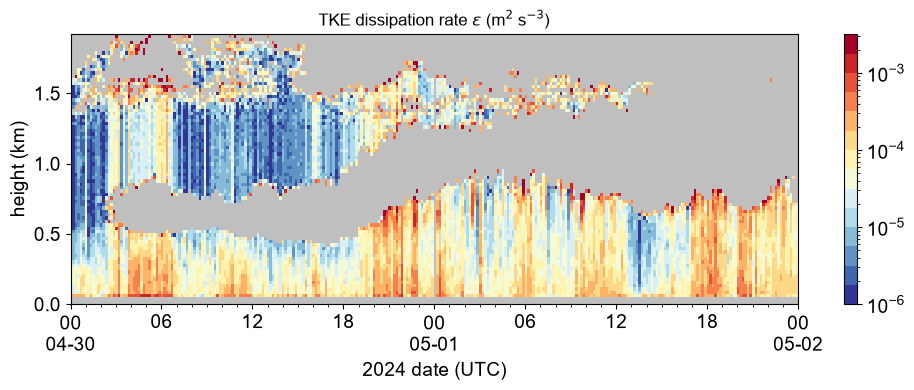

In [ ]:
d = read_epsilon_nc("epsilon_data/epsi_stare_vn_chunks_r20260517_2352.nc")

t0 = DateTime(2024, 4, 30, 0)
t1 = DateTime(2024, 5, 2, 0)
s = subset_time(d, t0, t1)
println("chunks in window: ", length(s.tst),
        ";  finite fraction: ", round(count(isfinite, s.eps) / length(s.eps), digits=3),
        ";  positive fraction: ", round(count(>(0), s.eps) / length(s.eps), digits=3))
fig = plot_epsilon_th(d, t0, t1; 
        zmax=2000, vmin=-6, vmax=-2.5, ncolors=14, gapfac=3, title="TKE dissipation rate \$\\varepsilon\$ (m\$^2\$ s\$^{-3}\$)")

[savefig("epsilon_timeheight_0430-0502.$(fmt)") for fmt in ["png", "pdf", "svg"]]
fig

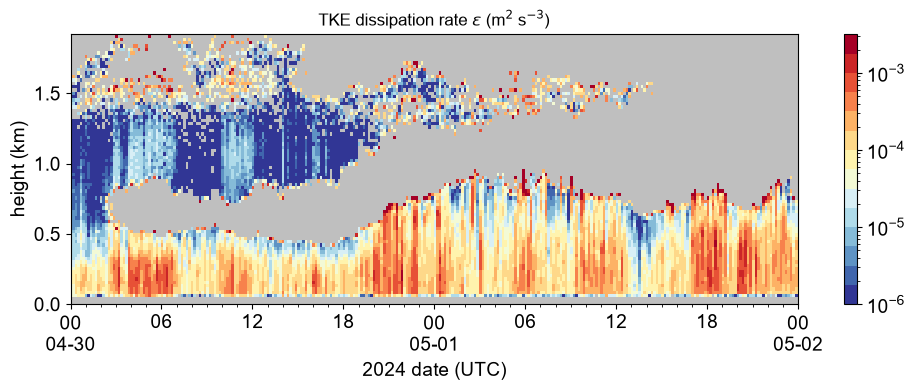

In [25]:
e = read_epsilon_nc("epsilon_data/epsi_stare_vn_chunks_r20260517_1959.nc")
fig = plot_epsilon_th(e, t0, t1; 
        zmax=2000, vmin=-6, vmax=-2.5, ncolors=14, gapfac=3, title="TKE dissipation rate \$\\varepsilon\$ (m\$^2\$ s\$^{-3}\$)")

This older retrieval is prbably contaminated by rolloff of energy outside the inertial scale, and filtering by correlation of overlapping adjacent beams.